# 洛伦兹函数（Lorentzian Function）

> 来源：Weisstein, Eric W. "Lorentzian Function." From *MathWorld*—A Wolfram Resource.
> <https://mathworld.wolfram.com/LorentzianFunction.html>
>
> 本文为根据该页面整理的笔记（公式与要点）加演示代码。

## 定义

洛伦兹函数只有一个峰，中心为 $x_0$，宽度参数为 $\Gamma$：

$$
L(x)=\frac{1}{\pi}\,\frac{\frac{1}{2}\Gamma}{(x-x_0)^2+\left(\frac{1}{2}\Gamma\right)^2}
$$

它描述某些谱线的线形，也是柯西分布（Cauchy distribution）的概率密度函数。

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad


def lorentzian(x, x0=0.0, gamma=2.0):
    """归一化洛伦兹函数，gamma 为半高全宽 (FWHM)"""
    hw = gamma / 2  # 半高半宽 (HWHM)
    return hw / (np.pi * ((x - x0) ** 2 + hw**2))

## 主要性质

记 $u = x - x_0$。

| 性质 | 结果 |
|---|---|
| 归一化 | $\displaystyle\int_{-\infty}^{\infty} L(x)\,dx = 1$ |
| 极大值位置 | $x = x_0$ |
| 峰值 | $L(x_0)=\dfrac{2}{\pi\Gamma}$ |
| 半高位置 | $x = x_0 \pm \frac{1}{2}\Gamma$ |
| 半高全宽（FWHM） | $\Gamma$ |
| 拐点 | $x = x_0 \pm \dfrac{\sqrt{3}}{6}\Gamma$ |
| 拐点处函数值 | $\dfrac{3}{2\pi\Gamma}$ |

### 数值验证

In [13]:
x0, gamma = 1.5, 0.8

area, _ = quad(lorentzian, -np.inf, np.inf, args=(x0, gamma))
peak = lorentzian(x0, x0, gamma)
half = lorentzian(x0 + gamma / 2, x0, gamma)
x_inf = x0 + np.sqrt(3) / 6 * gamma

print(f"面积            = {area:.6f}  (理论 1)")
print(f"峰值            = {peak:.6f}  (理论 2/(πΓ) = {2 / (np.pi * gamma):.6f})")
print(f"半高处/峰值      = {half / peak:.6f}  (理论 0.5)")
print(f"拐点处函数值      = {lorentzian(x_inf, x0, gamma):.6f}  (理论 3/(2πΓ) = {3 / (2 * np.pi * gamma):.6f})")

面积            = 1.000000  (理论 1)
峰值            = 0.795775  (理论 2/(πΓ) = 0.795775)
半高处/峰值      = 0.500000  (理论 0.5)
拐点处函数值      = 0.596831  (理论 3/(2πΓ) = 0.596831)


### 导数

$$
L'(x) = -\frac{16\,u\,\Gamma}{\pi\left(4u^2+\Gamma^2\right)^2}
$$

$$
L''(x) = \frac{16\,\Gamma\left(12u^2-\Gamma^2\right)}{\pi\left(4u^2+\Gamma^2\right)^3}
$$

$L'=0$ 只在 $x=x_0$ 处成立，这里是极大值。令 $L''=0$，得 $u^2=\Gamma^2/12$，也就是上表中的拐点。

L'  最大误差: 1.2195041378755891e-05
L'' 最大误差: 0.003034093348697994


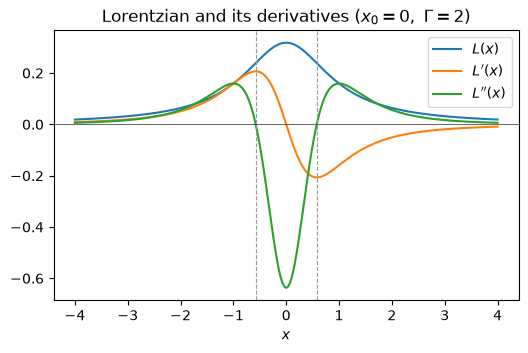

In [14]:
x = np.linspace(-4, 4, 2001)
x0, gamma = 0.0, 2.0
u = x - x0

L = lorentzian(x, x0, gamma)
dL = -16 * u * gamma / (np.pi * (4 * u**2 + gamma**2) ** 2)
d2L = 16 * gamma * (12 * u**2 - gamma**2) / (np.pi * (4 * u**2 + gamma**2) ** 3)

# 和数值差分对比，检验解析式
print("L'  最大误差:", np.abs(dL - np.gradient(L, x)).max())
print("L'' 最大误差:", np.abs(d2L - np.gradient(np.gradient(L, x), x)).max())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x, L, label="$L(x)$")
ax.plot(x, dL, label="$L'(x)$")
ax.plot(x, d2L, label="$L''(x)$")
for xi in (x0 - np.sqrt(3) / 6 * gamma, x0 + np.sqrt(3) / 6 * gamma):
    ax.axvline(xi, color="0.6", ls="--", lw=0.8)  # 拐点
ax.axhline(0, color="0.3", lw=0.6)
ax.set_xlabel("$x$")
ax.legend()
ax.set_title(r"Lorentzian and its derivatives ($x_0=0,\ \Gamma=2$)")
plt.show()

### 参数的作用：$x_0$ 平移，$\Gamma$ 控制宽度

$\Gamma$ 越大，峰越宽也越矮，但面积始终是 1。

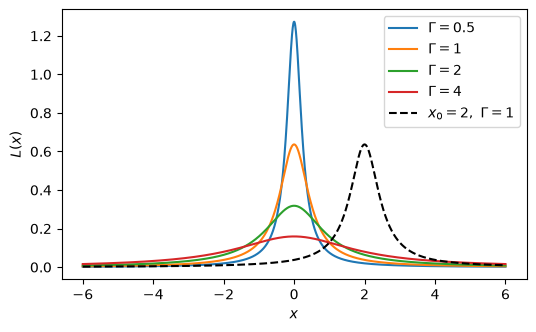

In [15]:
x = np.linspace(-6, 6, 1201)

fig, ax = plt.subplots(figsize=(6, 3.5))
for gamma in (0.5, 1, 2, 4):
    ax.plot(x, lorentzian(x, 0, gamma), label=rf"$\Gamma={gamma}$")
ax.plot(x, lorentzian(x, 2, 1), "k--", label=r"$x_0=2,\ \Gamma=1$")
ax.set_xlabel("$x$")
ax.set_ylabel("$L(x)$")
ax.legend()
plt.show()

## 与高斯函数对比

FWHM 和面积都相同时，洛伦兹峰的峰值更低（$1/\pi \approx 0.318$，高斯约为 0.470），尾部更厚：远处按 $1/x^2$ 衰减，而高斯函数按 $e^{-x^2}$ 衰减。这也是 XPS、Raman 拟合中常用 Voigt 或 Gaussian–Lorentzian 混合线形的原因。

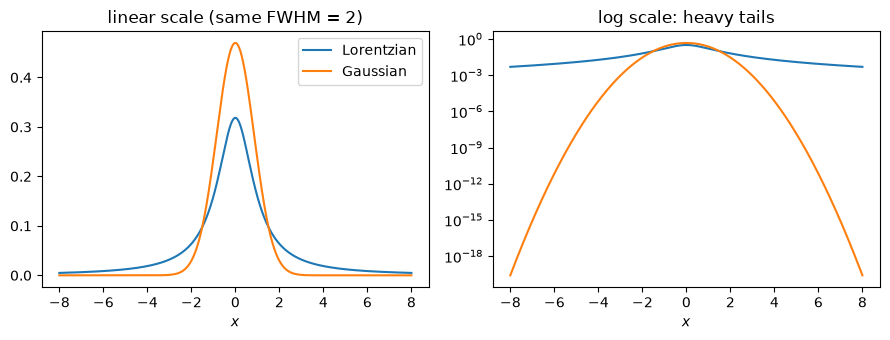

In [16]:
def gaussian(x, x0=0.0, fwhm=2.0):
    """归一化高斯函数，参数为 FWHM"""
    sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
    return np.exp(-((x - x0) ** 2) / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))


x = np.linspace(-8, 8, 1601)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
for ax in (ax1, ax2):
    ax.plot(x, lorentzian(x, 0, 2), label="Lorentzian")
    ax.plot(x, gaussian(x, 0, 2), label="Gaussian")
    ax.set_xlabel("$x$")
ax1.set_title("linear scale (same FWHM = 2)")
ax2.set_yscale("log")
ax2.set_title("log scale: heavy tails")
ax1.legend()
plt.tight_layout()
plt.show()

## 傅里叶变换

采用约定 $\mathcal{F}[f](k)=\int_{-\infty}^{\infty} f(x)\,e^{-2\pi i k x}\,dx$，则

$$
\mathcal{F}_x\big[L(x)\big](k)=e^{-2\pi i k x_0-\pi\Gamma|k|}
$$

也就是说，在频域里它是一个指数衰减，衰减速率与 $\Gamma$ 成正比；如果 $x_0 \neq 0$，还会多出一个相位因子。反过来说，时域里按指数衰减的振荡，经过傅里叶变换后得到的谱线就是洛伦兹线形，这也是寿命展宽产生洛伦兹线形的原因。

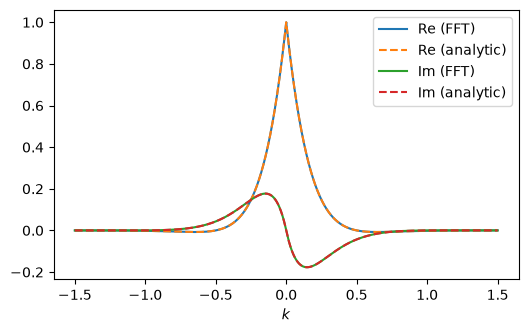

最大误差: 0.00031830988203018773


In [17]:
# 用 FFT 数值计算傅里叶变换，与解析式对比
x0, gamma = 0.5, 2.0
N, Lbox = 2**16, 4000.0  # 取样范围要足够宽，因为尾部衰减很慢
dx = Lbox / N
x = (np.arange(N) - N // 2) * dx
f = lorentzian(x, x0, gamma)

F_num = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(f))) * dx
k = np.fft.fftshift(np.fft.fftfreq(N, d=dx))
F_ana = np.exp(-2j * np.pi * k * x0 - np.pi * gamma * np.abs(k))

mask = np.abs(k) < 1.5
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(k[mask], F_num.real[mask], label="Re (FFT)")
ax.plot(k[mask], F_ana.real[mask], "--", label="Re (analytic)")
ax.plot(k[mask], F_num.imag[mask], label="Im (FFT)")
ax.plot(k[mask], F_ana.imag[mask], "--", label="Im (analytic)")
ax.set_xlabel("$k$")
ax.legend()
plt.show()

print("最大误差:", np.abs(F_num - F_ana)[mask].max())

## 其他要点

- 可以延拓到复平面。原页面画了实部、虚部以及等值线图。
- 可以用作切趾函数（apodization function），但对应的仪器函数没有简单的解析形式。
## 特例：$x_0=0,\ \Gamma=2$

$$
L(x)=\frac{1}{\pi(1+x^2)}
$$

峰值为 $1/\pi\approx0.318$，FWHM 为 2。不归一化的 $1/(1+x^2)$ 形状完全相同，只是峰值变成 1。

下面的代码仿照 MathWorld 的图（Mathematica 风格：坐标轴穿过原点、红色曲线）：

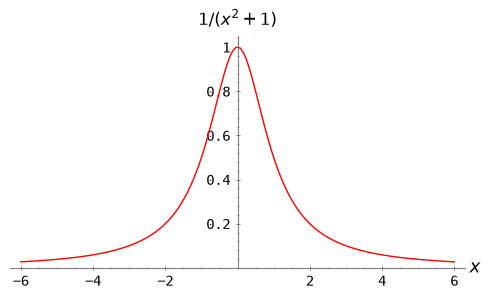

In [18]:
from matplotlib.ticker import AutoMinorLocator


def lorentzian_simple(x):
    """洛伦兹函数（不归一化，x0=0, Γ=2）：1/(1+x²)，峰值为 1。"""
    return 1 / (1 + x**2)


x = np.linspace(-6, 6, 601)  # 点数取奇数，保证采到 x=0，峰顶不被削平
y = lorentzian_simple(x)

fig, ax = plt.subplots(figsize=(5, 3.1))
ax.plot(x, y, color="red", lw=1)

ax.spines[["top", "right"]].set_visible(False)
ax.spines["left"].set_position("zero")
ax.spines["bottom"].set_position("zero")
for s in ax.spines.values():
    s.set_color("0.5")

ax.set_xlim(-6.3, 6.3)
ax.set_ylim(0, y.max() * 1.05)
ax.set_xticks([-6, -4, -2, 2, 4, 6])
ax.yaxis.set_major_formatter(lambda v, _: "" if v == 0 else f"{v:g}")
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
ax.tick_params(which="both", direction="inout", color="0.5")
ax.tick_params(which="minor", length=2)
for lab in ax.get_xticklabels() + ax.get_yticklabels():
    lab.set_fontfamily("monospace")

ax.text(1.01, 0, "$x$", transform=ax.get_yaxis_transform(), va="center", fontsize=13)
ax.text(0, 1.03, r"$1/(x^2+1)$", transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=12)

fig.tight_layout()
plt.show()

## 相关条目（MathWorld）

- [Cauchy Distribution](https://mathworld.wolfram.com/CauchyDistribution.html)
- [Fourier Transform—Lorentzian Function](https://mathworld.wolfram.com/FourierTransformLorentzianFunction.html)
- [Gaussian Function](https://mathworld.wolfram.com/GaussianFunction.html)
- [Hyperbolic Secant](https://mathworld.wolfram.com/HyperbolicSecant.html)
- [Logistic Distribution](https://mathworld.wolfram.com/LogisticDistribution.html)
- [Witch of Agnesi](https://mathworld.wolfram.com/WitchofAgnesi.html)
- [Damped Exponential Cosine Integral](https://mathworld.wolfram.com/DampedExponentialCosineIntegral.html)